# 01 · Explore the TREC Clinical Trials 2021/2022 data

What the patients, labels and trials look like before any modelling. Inputs are the tables written by `scripts/build_trec_tables.py` in `<data_dir>/processed/`.

Labels: **2 = eligible**, **1 = excluded** (relevant but fails a criterion), **0 = not relevant**.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from clinreason.config import load_config

pd.set_option('display.max_colwidth', 120)
PROC = Path(load_config()['data_dir']) / 'processed'
patients = pd.read_json(PROC / 'patients.jsonl', lines=True)
labels = pd.read_json(PROC / 'labels.jsonl', lines=True)
trials = pd.read_json(PROC / 'trials.jsonl', lines=True)
stats = json.loads((PROC / 'stats.json').read_text())
LABEL = {2: 'eligible', 1: 'excluded', 0: 'not relevant'}
print(len(patients), 'patients |', len(labels), 'labelled pairs |', len(trials), 'judged trials')

125 patients | 71226 labelled pairs | 48714 judged trials


## 1. Label balance

In [2]:
counts = (labels.assign(label=labels.label.map(LABEL)).groupby(['year', 'label']).size().unstack())
counts['total'] = counts.sum(axis=1)
counts

label,eligible,excluded,not relevant,total
year,,,,
2021,5570,6019,24243,35832
2022,3939,3036,28419,35394


label,not relevant,excluded,eligible
count,125.0,125.0,125.0
mean,421.3,72.4,76.1
std,174.2,62.9,56.8
min,123.0,1.0,6.0
25%,285.0,26.0,33.0
50%,388.0,52.0,60.0
75%,524.0,105.0,115.0
max,932.0,339.0,306.0


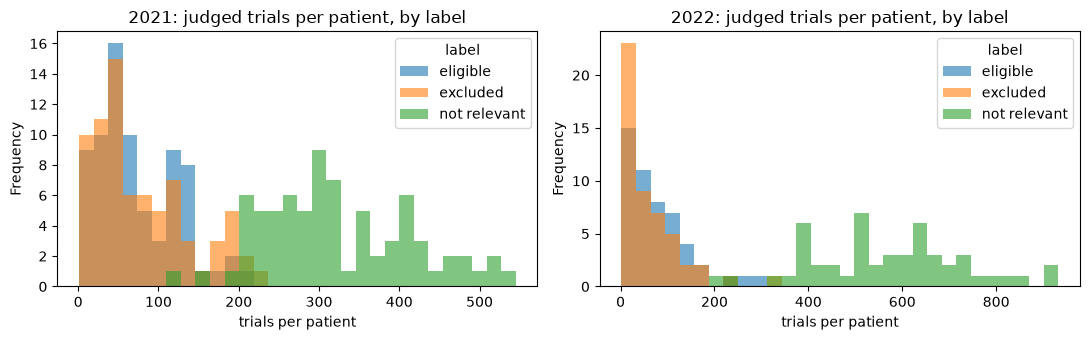

In [3]:
per_patient = labels.groupby(['patient_id', 'label']).size().unstack(fill_value=0).rename(columns=LABEL)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, year in zip(ax, (2021, 2022)):
    sub = per_patient[per_patient.index.str.startswith(str(year))]
    sub[['eligible', 'excluded', 'not relevant']].plot.hist(
        bins=30, alpha=0.6, ax=a, title=f'{year}: judged trials per patient, by label')
    a.set_xlabel('trials per patient')
plt.tight_layout()
per_patient.describe().round(1)

## 2. One patient and three of their judged trials

In [4]:
pid = '2022-1'
print(patients.set_index('patient_id').loc[pid, 'text'])

A 19-year-old male came to clinic with some sexual concern. He recently engaged in a relationship and is worried about the satisfaction of his girlfriend. He has a "baby face" according to his girlfriend's statement and he is not as muscular as his classmates. On physical examination, there is some pubic hair and poorly developed secondary sexual characteristics. He is unable to detect coffee smell during the examination, but the visual acuity is normal. Ultrasound reveals the testes volume of 1-2 ml. The hormonal evaluation showed serum testosterone level of 65 ng/dL with low levels of GnRH.


In [5]:
T = trials.set_index('nct_id')

def show_trial(nct, chars=1500):
    t = T.loc[nct]
    age = (t.minimum_age_years, t.maximum_age_years)
    print(f'{nct} | {t.brief_title}')
    print(f'conditions: {t.conditions} | sex: {t.gender} | age (years): {age} | '
          f'healthy volunteers: {t.healthy_volunteers} | split: {t.split_status}')
    text = lambda v: v if isinstance(v, str) else '(none)'
    if t.split_status in ('unsectioned', 'no_criteria'):
        print('--- CRITERIA (no section headers) ---')
        print(text(t.criteria_text)[:chars]); return
    print('--- INCLUSION ---'); print(text(t.inclusion_text)[:chars])
    print('--- EXCLUSION ---'); print(text(t.exclusion_text)[:chars])

mine = labels[labels.patient_id == pid]
examples = {lab: mine[mine.label == lab].nct_id.iloc[0] for lab in (2, 1, 0)}
examples

{2: 'NCT00161421', 1: 'NCT00001412', 0: 'NCT00000409'}

### Eligible (label 2)

In [6]:
show_trial(examples[2])

NCT00161421 | Oral Androgens in Man-3 (ORAL T-3) Pharmacokinetics of Oral Testosterone
conditions: ['Contraception', 'Hypogonadism'] | sex: Male | age (years): (np.float64(18.0), np.float64(50.0)) | healthy volunteers: 1.0 | split: both
--- INCLUSION ---
-  Male 18-50 yrs old

          -  In good general health based on normal screening evaluation (consisting of medical
             history, physical exam, normal serum chemistry, hematology, and baseline hormone
             levels)
--- EXCLUSION ---
-  Poor general health, with abnormal blood results at screening

          -  A known history of alcohol or drug abuse

          -  Participation in a long-term male contraceptive study within three months of screening


### Excluded (label 1)

In [7]:
show_trial(examples[1])

NCT00001412 | Effects on the Brain of Lupron Induced Hypogonadotropic Hypogonadism With and Without Testosterone Replacement
conditions: ['Hypogonadism'] | sex: Male | age (years): (np.float64(nan), np.float64(nan)) | healthy volunteers: 1.0 | split: unsectioned
--- CRITERIA (no section headers) ---
Age 18-45.

        Males.

        No current mood symptoms.

        No past psychiatric history.

        Not taking ongoing medications.

        No medical illnesses.


### Not relevant (label 0)

In [8]:
show_trial(examples[0], chars=600)

NCT00000409 | Spine Patient Outcomes Research Trial (SPORT): Degenerative Spondylolisthesis With Spinal Stenosis
conditions: ['Spondylolisthesis', 'Spinal Stenosis', 'Low Back Pain'] | sex: All | age (years): (np.float64(18.0), np.float64(nan)) | healthy volunteers: 0.0 | split: both
--- INCLUSION ---
-  Duration of Symptoms: 12 or more weeks.

          -  Treatments Tried: Nonsteroidal. anti-inflammatory medical therapy and physical
             therapy.

          -  Surgical Screening: Pain in low back, buttocks, or lower extremity that becomes worse
             with lumbar extension. Must be confirmed by evidence of central or central-lateral
             compression of the cauda equina by a degenerative lesion of the facet joint, disc, or
             ligamentum flavum on MRI, computed tomography scans, or myelograms.

          -  Tests: MRI to confirm diagnosis and level(s).
--- EXCLUSION ---
-  Previous lumbar spine surgery.

          -  Not a surgical candidate for any of t

## 3. How long are the criteria? (drives prompt length and GPU cost)

In [9]:
words = lambda s: s.fillna('').str.split().str.len()
lengths = pd.DataFrame({
    'patient note': words(patients.text).describe(),
    'inclusion': words(trials.inclusion_text).describe(),
    'exclusion': words(trials.exclusion_text).describe(),
    'full criteria': words(trials.criteria_text).describe(),
}).round(0)
lengths

,patient note,inclusion,exclusion,full criteria
count,125.0,48714.0,48714.0,48714.0
mean,120.0,101.0,121.0,238.0
std,36.0,142.0,163.0,272.0
min,51.0,0.0,0.0,0.0
25%,92.0,25.0,23.0,71.0
50%,117.0,55.0,61.0,140.0
75%,144.0,118.0,149.0,296.0
max,218.0,2453.0,1861.0,2539.0


share of trials over 1,000 words: 0.027


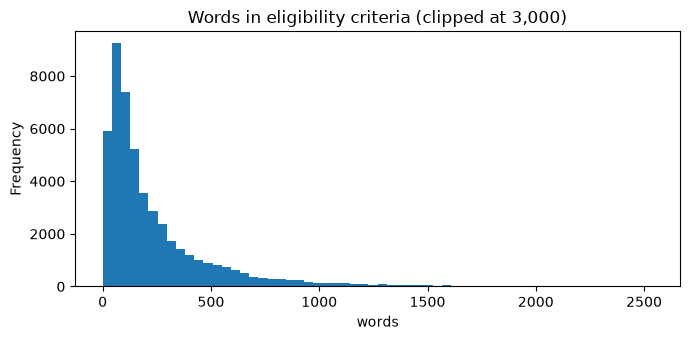

In [10]:
full = words(trials.criteria_text)
ax = full.clip(upper=3000).plot.hist(bins=60, figsize=(7, 3.5),
    title='Words in eligibility criteria (clipped at 3,000)')
ax.set_xlabel('words'); plt.tight_layout()
print('share of trials over 1,000 words:', round((full > 1000).mean(), 3))

## 4. Inclusion / exclusion split quality

`both` = both sections found; `unsectioned` = free text with no recognisable headers (kept whole in `criteria_text`).

In [11]:
split = trials.split_status.value_counts().to_frame('trials')
split['share'] = (split.trials / len(trials)).round(4)
split

,trials,share
split_status,,
both,45561,0.9353
unsectioned,1974,0.0405
inclusion_only,1156,0.0237
exclusion_only,12,0.0002
no_criteria,11,0.0002


In [12]:
unsectioned = trials[trials.split_status == 'unsectioned'].nct_id
for nct in unsectioned.sample(3, random_state=0):
    print(nct, '|', T.loc[nct, 'brief_title'])
    print(T.loc[nct, 'criteria_text'][:500]); print('=' * 80)

NCT00000155 | The Collaborative Longitudinal Evaluation of Keratoconus (CLEK) Study
Patients with keratoconus were eligible if they were at least 12 years old; had an
        irregular cornea as determined by keratometry, retinoscopy, or direct ophthalmoscopy in at
        least one eye; had Vogt's striae, Fleischer's ring, or corneal scarring characteristic of
        keratoconus in at least one eye; and planned to stay in the area for at least 3 years. They
        were ineligible if they had bilateral corneal transplants or bilateral nonkeratoconic eye
        disease (catar
NCT00002654 | Radiation Therapy With or Without Cisplatin in Treating Patients With Advanced Head and Neck Cancer
DISEASE CHARACTERISTICS: Histologically documented squamous cell cancer of the head and
        neck in the following sites: Hypopharynx Larynx Oral cavity Oropharynx Stage III/IV disease
        No distant metastases by the following: Chest x-ray (all patients) Liver ultrasound or CT
        and bon

## 5. Structured eligibility fields (usable without an LLM)

In [13]:
pd.DataFrame({
    'has minimum age': trials.minimum_age_years.notna().mean(),
    'has maximum age': trials.maximum_age_years.notna().mean(),
    'sex restricted': (trials.gender.isin(['Female', 'Male'])).mean(),
    'healthy volunteers known': trials.healthy_volunteers.notna().mean(),
}, index=['share of judged trials']).T.round(3)

,share of judged trials
has minimum age,0.898
has maximum age,0.530
sex restricted,0.158
healthy volunteers known,0.980


## Observations to carry forward

- Most judged pairs are *not relevant*; *eligible* vs *excluded* is the hard, clinically meaningful distinction.
- Criteria are long: prompt length, not patient-note length, sets GPU cost.
- Age and sex are structured fields; they can be checked by code before any LLM call.
- Some criteria are scores or nested logic (e.g. NCT02006511: "at least 8 points" from weighted risk factors), which a flat AND/OR list cannot express (Step 3).